# Project 2 · Milestone 1 — Environment Setup & CLIP Text→Embedding Pipeline

**Goal:** show that our environment works end to end: load CLIP, tokenize our captions, compute **text and image embeddings**, and verify that matching image–caption pairs land close together.

Why CLIP? Stable Diffusion 1.5 uses the **text encoder of CLIP ViT-L/14** to turn a prompt into the vectors that guide image generation. We use that same model here, so this pipeline is the exact text-conditioning path we build on in Milestone 2.

**Runtime:** Colab with a GPU (Runtime → Change runtime type → T4 GPU). About 5 minutes.

**Input:** the `flickr30k_subset` folder (or zip) made by `01_dataset_preparation.ipynb`.

## 1. Install the environment
The assignment asks for PyTorch + Hugging Face Diffusers + Transformers + CLIP. Colab already has PyTorch; we add the rest. CLIP is loaded through Transformers.

In [7]:
!pip install -q diffusers transformers accelerate ftfy

## 2. Check versions and GPU, and save them
Recording exact versions makes the environment reproducible: the README tells teammates to install these same versions. This cell writes `environment.json` and `requirements.txt`.

In [8]:
import os, json, platform, sys
import torch, transformers, diffusers

env = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "diffusers": diffusers.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
}
for k, v in env.items():
    print(f"{k:15s} {v}")

if not env["cuda_available"]:
    print("\nWARNING: no GPU found. It will still run on CPU, just slower. "
          "In Colab: Runtime -> Change runtime type -> T4 GPU.")

with open("environment.json", "w") as f:
    json.dump(env, f, indent=2)

python          3.13.15
torch           2.11.0+cu130
transformers    5.20.1
diffusers       0.41.0
cuda_available  True
gpu             Tesla T4


In [9]:
!pip freeze | grep -iE "^(torch|torchvision|transformers|diffusers|accelerate|ftfy|pillow|numpy|pandas|datasets|imagehash)==" > requirements.txt
!cat requirements.txt

accelerate==1.15.0
datasets==4.8.5
diffusers==0.41.0
ftfy==6.3.1
numpy==2.1.3
pandas==2.2.3
pillow==11.3.0
torch==2.11.0+cu130
torchvision==0.26.0+cu130
transformers==5.20.1


## 3. Settings

In [10]:
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

SEED        = 42
MODEL_NAME  = "openai/clip-vit-large-patch14"   # same text encoder Stable Diffusion 1.5 uses
SAMPLE_SIZE = 500     # pairs to embed (set to len(df) to embed all 2,000)
BATCH_SIZE  = 32

DATA_DIR = "data/flickr30k_subset"
ZIP_PATH = "flickr30k_subset.zip"        # or "/content/drive/MyDrive/flickr30k_subset.zip"
EMB_DIR  = "embeddings"
os.makedirs(EMB_DIR, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)
print("device:", device)

device: cuda


## 4. Load the dataset from notebook 1
**Before running:** click the folder icon on the left and drag in `flickr30k_subset.zip` from notebook 1. Wait until the upload finishes. This cell finds the zip by itself, even if its name changed.

In [11]:
# Rebuilds the same 2,000-pair dataset as notebook 1, directly from Hugging Face (no upload needed).
# Same seed and rules as notebook 1. Takes about 5-10 minutes.
!pip install -q datasets imagehash
import os, re, json, hashlib
from collections import Counter
import numpy as np, pandas as pd, imagehash
from PIL import Image
from datasets import load_dataset

SEED, TARGET_PAIRS, IMG_SIZE, MIN_SIDE, MAX_ASPECT = 42, 2000, 512, 256, 2.0
MIN_WORDS, MAX_WORDS, TARGET_WORDS, NEAR_DUP_DIST = 6, 30, 15, 4
DATA_DIR = "data/flickr30k_subset"
IMG_DIR = os.path.join(DATA_DIR, "images")
os.makedirs(IMG_DIR, exist_ok=True)

BLOCKLIST = {"nude", "naked", "topless", "sexy", "blood", "bloody", "gun", "guns",
             "rifle", "pistol", "weapon", "weapons", "corpse", "kill", "killing"}

def clean_caption(text):
    t = text.strip()
    t = re.sub(r"\s+([.,!;:'])", r"\1", t)
    t = re.sub(r"\s+", " ", t)
    t = t.strip(" .")
    if t:
        t = t[0].upper() + t[1:]
    return t

def word_count(t):
    return len(t.split())

def caption_ok(t):
    n = word_count(t)
    if n < MIN_WORDS or n > MAX_WORDS or "?" in t:
        return False
    if sum(c.isalpha() for c in t) / max(len(t), 1) < 0.7:
        return False
    return not (set(re.findall(r"[a-z]+", t.lower())) & BLOCKLIST)

def pick_caption(captions):
    valid = []
    for c in captions:
        c = clean_caption(c)
        if caption_ok(c) and c not in valid:
            valid.append(c)
    if not valid:
        return None, []
    return min(valid, key=lambda c: abs(word_count(c) - TARGET_WORDS)), valid

def center_crop_resize(img):
    img = img.convert("RGB")
    w, h = img.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    return img.crop((left, top, left + s, top + s)).resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)

ds = load_dataset("lmms-lab-encoder/flickr30k", split="test", streaming=True).shuffle(seed=SEED, buffer_size=2000)
records, seen_captions, seen_hashes = [], set(), []
for ex in ds:
    img = ex["image"]
    w, h = img.size
    if min(w, h) < MIN_SIDE or max(w, h) / min(w, h) > MAX_ASPECT:
        continue
    best, valid = pick_caption(ex["caption"])
    if best is None or best.lower() in seen_captions:
        continue
    ph = imagehash.phash(img.convert("RGB"))
    if any(ph - prev <= NEAR_DUP_DIST for prev in seen_hashes):
        continue
    fname = os.path.splitext(ex["filename"])[0] + ".jpg"
    center_crop_resize(img).save(os.path.join(IMG_DIR, fname), quality=95)
    seen_captions.add(best.lower())
    seen_hashes.append(ph)
    records.append({"image_id": ex["img_id"], "filename": fname, "caption": best,
                    "n_words": word_count(best), "alt_captions": json.dumps(valid),
                    "orig_width": w, "orig_height": h})
    if len(records) % 250 == 0:
        print(f"kept {len(records)} / {TARGET_PAIRS}")
    if len(records) >= TARGET_PAIRS:
        break

df = pd.DataFrame(records).sample(frac=1, random_state=SEED).reset_index(drop=True)
n = len(df)
df["split"] = ["train"] * int(0.8 * n) + ["val"] * int(0.1 * n) + ["test"] * (n - int(0.8 * n) - int(0.1 * n))
df.to_csv(os.path.join(DATA_DIR, "metadata.csv"), index=False)

check = hashlib.md5("|".join(sorted(df["filename"] + ":" + df["split"])).encode()).hexdigest()[:10]
print("pairs:", len(df), df["split"].value_counts().to_dict())
print("check code:", check, "(same as notebook 1)" if check == "477c680542" else "(DIFFERENT from notebook 1)")
df.head(3)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 6.0 MB/s eta 0:00:00


README.md:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

kept 250 / 2000
kept 500 / 2000
kept 750 / 2000
kept 1000 / 2000
kept 1250 / 2000
kept 1500 / 2000
kept 1750 / 2000
kept 2000 / 2000
pairs: 2000 {'train': 1600, 'val': 200, 'test': 200}
check code: 477c680542 (same as notebook 1)


,image_id,filename,caption,n_words,alt_captions,orig_width,orig_height,split
0,130,1042359076.jpg,Two little girls and an old man have a convers...,10,"[""A older man holds an object and is looking a...",500,333,train
1,12093,3207358897.jpg,An Asian girl performs a routine with two red ...,13,"[""An Asian girl performs a routine with two re...",500,375,train
2,10760,3049617203.jpg,Man wearing a red black and white jacket ridin...,18,"[""A man with a plaid shirt riding a bike going...",500,309,train


## 5. Load CLIP
CLIP has two encoders trained together on 400M image–text pairs:
- a **text encoder** (Transformer) that turns a caption into a vector
- an **image encoder** (Vision Transformer) that turns an image into a vector

Both vectors live in the same 768-dimensional space, so we can compare them directly. On GPU we use half precision (float16) to save memory.

In [12]:
from transformers import CLIPModel, CLIPProcessor

processor = CLIPProcessor.from_pretrained(MODEL_NAME)
tokenizer = processor.tokenizer
model = CLIPModel.from_pretrained(MODEL_NAME).to(device).eval()
if device == "cuda":
    model = model.half()

n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"Loaded {MODEL_NAME}: {n_params:.0f}M parameters")
print("text embedding size :", model.config.projection_dim)
print("max caption tokens  :", tokenizer.model_max_length)

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

Loaded openai/clip-vit-large-patch14: 428M parameters
text embedding size : 768
max caption tokens  : 77


## 6. Tokenization
Before the text encoder can read a caption, the **tokenizer** splits it into sub-word tokens and maps each to an ID. CLIP always works with exactly **77 tokens**: a start token, the caption, an end token, then padding.

In [13]:
caption = df.loc[0, "caption"]
enc = tokenizer(caption, padding="max_length", max_length=77, truncation=True)
ids = enc["input_ids"]
n_real = sum(enc["attention_mask"])

print("Caption:", caption)
print("Tokens :", tokenizer.convert_ids_to_tokens(ids[:n_real]))
print("IDs    :", ids[:n_real])
print(f"Real tokens: {n_real} | padded length: {len(ids)}")

Caption: Two little girls and an old man have a conversation
Tokens : ['<|startoftext|>', 'two</w>', 'little</w>', 'girls</w>', 'and</w>', 'an</w>', 'old</w>', 'man</w>', 'have</w>', 'a</w>', 'conversation</w>', '<|endoftext|>']
IDs    : [49406, 1237, 1274, 1917, 537, 550, 896, 786, 720, 320, 5690, 49407]
Real tokens: 12 | padded length: 77


Now check **every** caption in the dataset: if any were longer than 77 tokens, CLIP would silently cut off the end. Our 30-word limit from notebook 1 should keep all of them inside.

token length: min 9, mean 16.5, max 25
captions longer than 77 tokens: 0


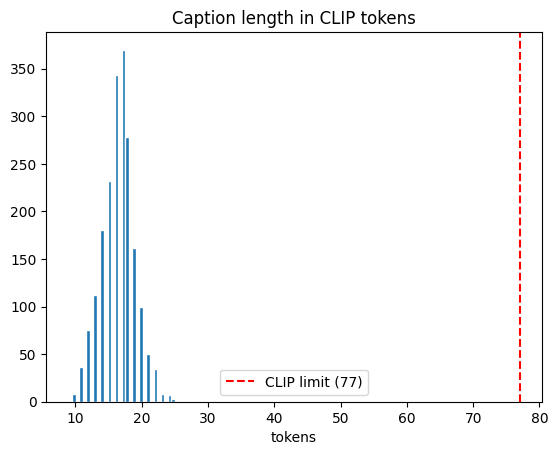

In [14]:
token_lens = np.array([len(x) for x in tokenizer(df["caption"].tolist(), truncation=False)["input_ids"]])
print(f"token length: min {token_lens.min()}, mean {token_lens.mean():.1f}, max {token_lens.max()}")
print("captions longer than 77 tokens:", int((token_lens > 77).sum()))

plt.hist(token_lens, bins=30, edgecolor="white")
plt.axvline(77, color="red", ls="--", label="CLIP limit (77)")
plt.title("Caption length in CLIP tokens"); plt.xlabel("tokens"); plt.legend(); plt.show()

## 7. Compute text and image embeddings
For each batch:
- **text:** tokenize → text Transformer → final "summary" vector → projection to 768-d
- **image:** CLIP's own resize/normalize → vision Transformer → projection to 768-d

Each embedding is then scaled to length 1, so the dot product of a text vector and an image vector is their **cosine similarity** (1 = same meaning, ~0 = unrelated).

In [15]:
sample = df.sample(min(SAMPLE_SIZE, len(df)), random_state=SEED).reset_index(drop=True)

@torch.no_grad()
def embed_texts(texts):
    inp = tokenizer(texts, padding="max_length", max_length=77, truncation=True, return_tensors="pt").to(device)
    out = model.text_model(input_ids=inp["input_ids"], attention_mask=inp["attention_mask"])
    emb = model.text_projection(out.pooler_output)
    return torch.nn.functional.normalize(emb.float(), dim=-1).cpu()

@torch.no_grad()
def embed_images(images):
    pix = processor(images=images, return_tensors="pt")["pixel_values"].to(device, model.dtype)
    out = model.vision_model(pixel_values=pix)
    emb = model.visual_projection(out.pooler_output)
    return torch.nn.functional.normalize(emb.float(), dim=-1).cpu()

text_chunks, image_chunks = [], []
for start in range(0, len(sample), BATCH_SIZE):
    batch = sample.iloc[start:start + BATCH_SIZE]
    text_chunks.append(embed_texts(batch["caption"].tolist()))
    imgs = [Image.open(os.path.join(DATA_DIR, "images", f)).convert("RGB") for f in batch["filename"]]
    image_chunks.append(embed_images(imgs))
    print(f"\rembedded {min(start + BATCH_SIZE, len(sample))}/{len(sample)}", end="")

text_emb = torch.cat(text_chunks)
image_emb = torch.cat(image_chunks)
print("\ntext embeddings :", tuple(text_emb.shape))
print("image embeddings:", tuple(image_emb.shape))

embedded 500/500
text embeddings : (500, 768)
image embeddings: (500, 768)


## 8. Token-level embeddings (what Stable Diffusion actually uses)
The single 768-d vector above is for comparing captions with images. Stable Diffusion instead uses the **full sequence of 77 token vectors** from the text encoder's last layer; its U-Net looks at these through cross-attention while it denoises. Here we produce that tensor for a few captions; this is the conditioning input for Milestone 2.

In [16]:
with torch.no_grad():
    inp = tokenizer(sample["caption"][:4].tolist(), padding="max_length", max_length=77,
                    truncation=True, return_tensors="pt").to(device)
    hidden = model.text_model(input_ids=inp["input_ids"], attention_mask=inp["attention_mask"]).last_hidden_state

print("token-level text embeddings:", tuple(hidden.shape), " -> (captions, tokens, hidden size)")

token-level text embeddings: (4, 77, 768)  -> (captions, tokens, hidden size)


## 9. Verify the pipeline: do matching pairs score higher?
If everything works, a caption should be much more similar to **its own image** than to a random image. We check two ways:

1. **Matched vs. random similarity:** the average cosine similarity of true pairs vs. mismatched pairs.
2. **Retrieval:** for each caption, rank all images in the sample by similarity. *Recall@K* = % of captions whose true image is in the top K. Random guessing would give K / sample size.

sample_size            500
mean_cos_matched       0.271
mean_cos_mismatched    0.097
text_to_image_R@1      78.400
text_to_image_R@5      95.400
text_to_image_R@10     98.000
image_to_text_R@1      78.800
image_to_text_R@5      96.000
random_chance_R@1      0.200


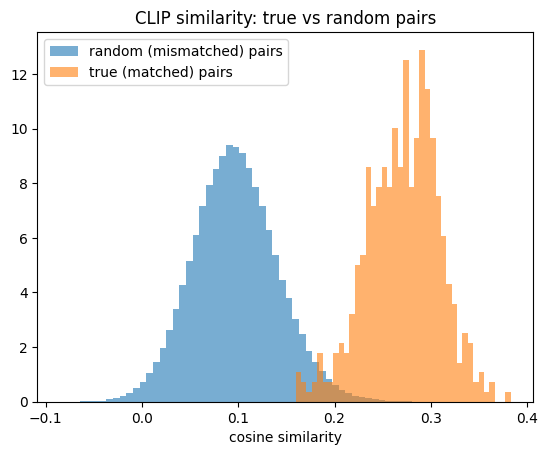

In [17]:
sims = (text_emb @ image_emb.T).numpy()          # [captions x images]
N = len(sims)
matched = np.diag(sims)
mismatched = sims[~np.eye(N, dtype=bool)]

def recall_at_k(sim, k):
    ranks = (-sim).argsort(axis=1)
    return 100 * np.mean([i in ranks[i, :k] for i in range(len(sim))])

results = {
    "sample_size": N,
    "mean_cos_matched": float(matched.mean()),
    "mean_cos_mismatched": float(mismatched.mean()),
    "text_to_image_R@1": recall_at_k(sims, 1),
    "text_to_image_R@5": recall_at_k(sims, 5),
    "text_to_image_R@10": recall_at_k(sims, 10),
    "image_to_text_R@1": recall_at_k(sims.T, 1),
    "image_to_text_R@5": recall_at_k(sims.T, 5),
    "random_chance_R@1": 100 / N,
}
for k, v in results.items():
    print(f"{k:22s} {v:.3f}" if isinstance(v, float) else f"{k:22s} {v}")

plt.hist(mismatched, bins=60, alpha=0.6, density=True, label="random (mismatched) pairs")
plt.hist(matched, bins=40, alpha=0.6, density=True, label="true (matched) pairs")
plt.xlabel("cosine similarity"); plt.title("CLIP similarity: true vs random pairs"); plt.legend()
plt.savefig(os.path.join(EMB_DIR, "similarity_hist.png"), dpi=120, bbox_inches="tight"); plt.show()

## 10. See it working: caption → top 3 images
For a few captions, show the 3 images CLIP ranks as the best match. A green title marks the true image.

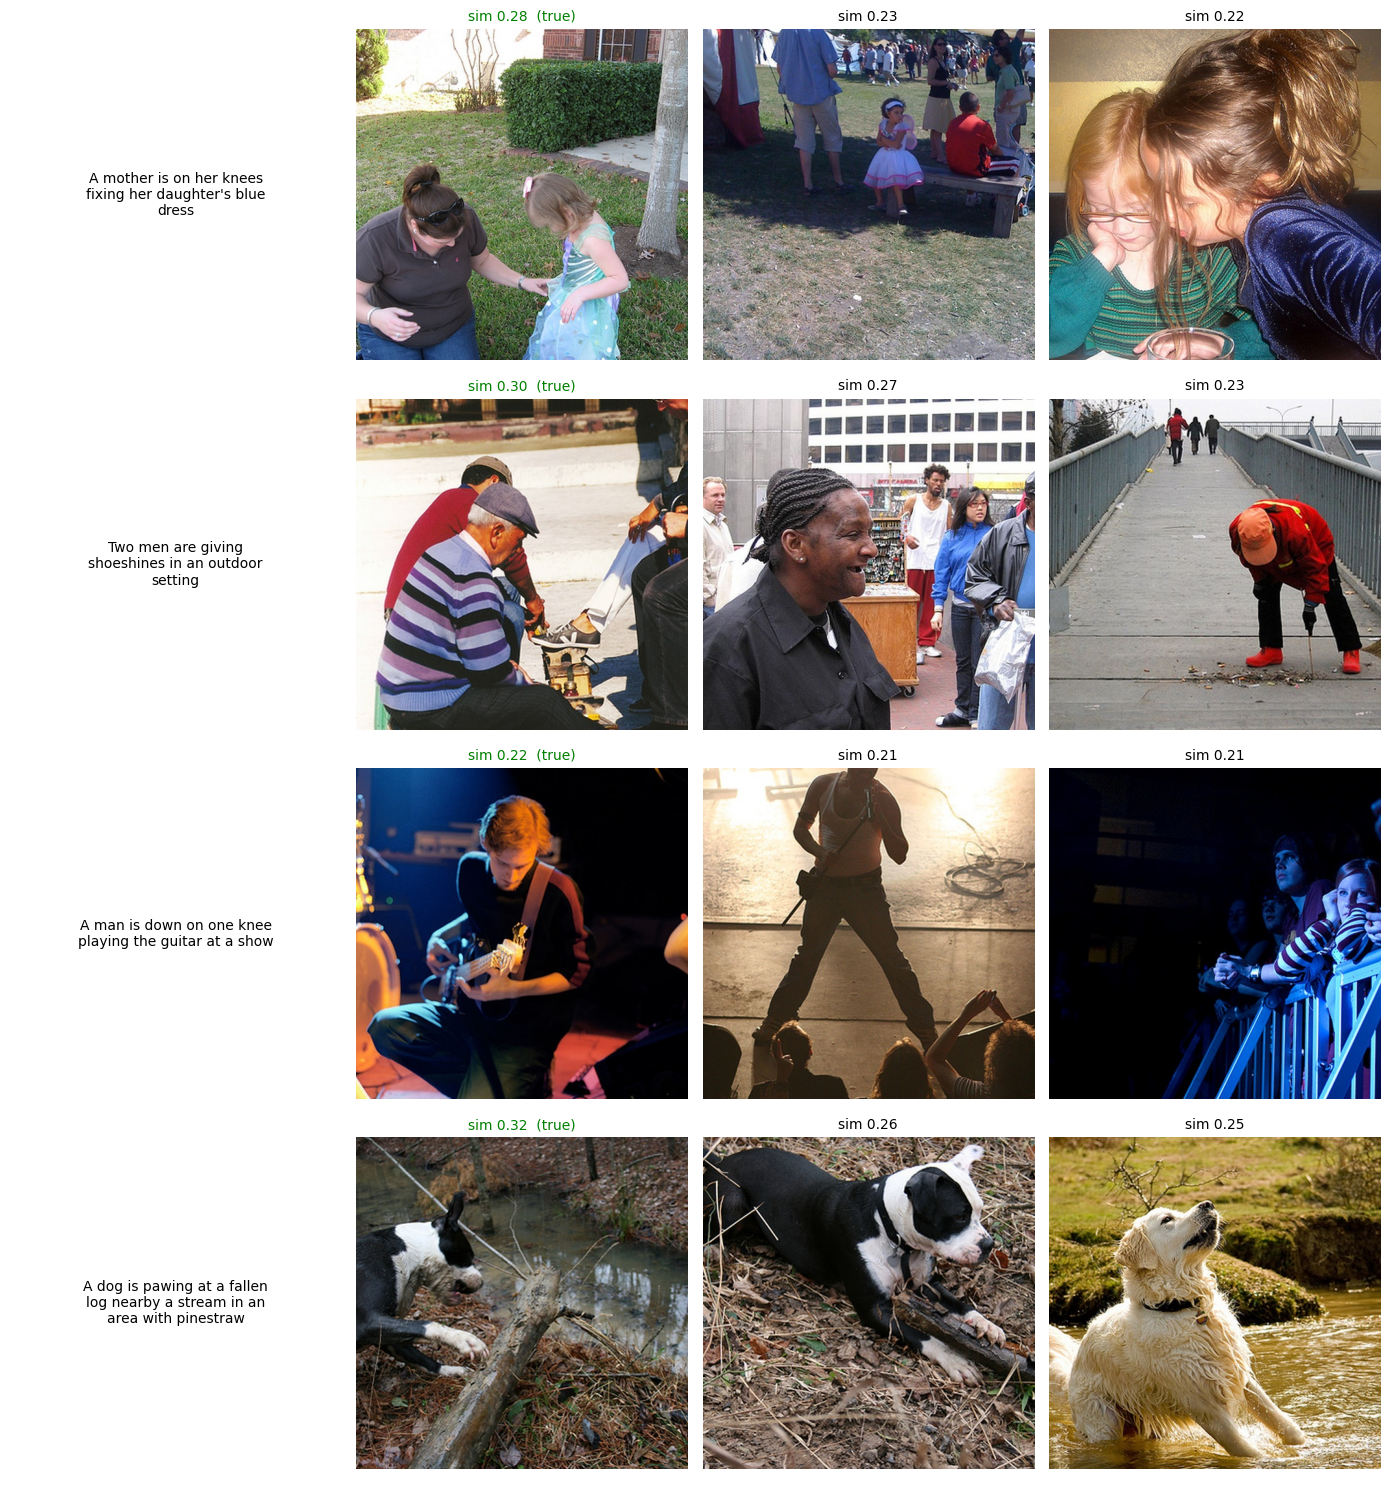

In [18]:
import textwrap
picks = np.random.default_rng(SEED).choice(N, 4, replace=False)
fig, axes = plt.subplots(4, 4, figsize=(14, 15))
for row, qi in zip(axes, picks):
    row[0].text(0.5, 0.5, "\n".join(textwrap.wrap(sample.loc[qi, "caption"], 28)),
                ha="center", va="center", fontsize=10, wrap=True)
    row[0].axis("off")
    for ax, j in zip(row[1:], (-sims[qi]).argsort()[:3]):
        ax.imshow(Image.open(os.path.join(DATA_DIR, "images", sample.loc[j, "filename"])))
        ax.set_title(f"sim {sims[qi, j]:.2f}" + ("  (true)" if j == qi else ""),
                     color="green" if j == qi else "black", fontsize=10)
        ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(EMB_DIR, "retrieval_examples.png"), dpi=110, bbox_inches="tight"); plt.show()

## 11. End-to-end checks
Automatic checks that the pipeline ran correctly. This cell stops with an error if anything is wrong.

In [19]:
assert text_emb.shape == image_emb.shape == (N, model.config.projection_dim), "wrong embedding shape"
assert torch.isfinite(text_emb).all() and torch.isfinite(image_emb).all(), "NaN/inf in embeddings"
assert torch.allclose(text_emb.norm(dim=-1), torch.ones(N), atol=1e-3), "embeddings not normalized"
assert hidden.shape[1:] == (77, model.config.text_config.hidden_size), "wrong token-level shape"
assert results["mean_cos_matched"] > results["mean_cos_mismatched"] + 0.05, "matched pairs not more similar"
assert results["text_to_image_R@1"] > 10 * results["random_chance_R@1"], "retrieval not better than chance"
print("All checks passed: the text -> embedding pipeline runs end to end and the embeddings are meaningful.")

All checks passed: the text -> embedding pipeline runs end to end and the embeddings are meaningful.


## 12. Save embeddings and results
Saved to `embeddings/` so later milestones can reuse them without recomputing.

In [20]:
np.save(os.path.join(EMB_DIR, "clip_text_emb.npy"), text_emb.numpy())
np.save(os.path.join(EMB_DIR, "clip_image_emb.npy"), image_emb.numpy())
sample[["filename", "caption", "split"]].to_csv(os.path.join(EMB_DIR, "embedded_pairs.csv"), index=False)
with open(os.path.join(EMB_DIR, "clip_results.json"), "w") as f:
    json.dump({"model": MODEL_NAME, "environment": env, **results}, f, indent=2)
print(sorted(os.listdir(EMB_DIR)))

['clip_image_emb.npy', 'clip_results.json', 'clip_text_emb.npy', 'embedded_pairs.csv', 'retrieval_examples.png', 'similarity_hist.png']
